# PanGenie in the 231-founder panel — benchmark

The production panel merges **78 founders genotyped from their own long-read assemblies**
(cactus) with **153 founders genotyped from short reads by PanGenie** against the
135-assembly graph. Two questions:

1. **Q1 — how much of a founder's variation does PanGenie recover** from short reads,
   compared with adding that founder's long-read assembly?
2. **Q2 — how different is the new mixed panel**, with its production QC, from the old
   GrENE-Net phase-1 SNP panel of the same 231 accessions?

**Metrics.** Against a truth genotype: **recall** = share of the variants the truth carries
that PanGenie calls; **precision** = share of PanGenie's variant calls the truth confirms;
**nRD** (non-reference discordance) = share of disagreeing genotypes among sites where either
side is non-reference. Plain genotype concordance is not reported: it is dominated by
ref/ref sites and sits above 99% whatever the quality.

**Analysis filter** throughout, unless stated: only variants the downstream analyses keep —
**not private (≥ 2 of 231 founders carry it) and call rate ≥ 50%** — judged on the production
panel record (for SV events, on the event's union of carriers / called founders). The section
"How the downstream variant filters change the metrics" shows the unfiltered numbers and the
stricter filters some analyses use.

**Production QC** throughout, unless marked raw: GQ < 20 → missing on the PanGenie record,
then het → missing per biallelic variant (inbred lines). All scoring is in the panel's own
**arch3 biallelic space** (each graph allele decomposed into the atomic variants on its path),
so a wrong allele in a multi-allelic bubble counts as wrong and a bubble counts once per
variant, not once per allele.

> **This is the similar-allele version.** SNPs and indels/MNPs ≤ 50 bp are scored exactly as
> in `pangenie_accuracy.ipynb`. **SVs (> 50 bp) are matched as events**: alleles of one graph
> bubble that are the same insertion or deletion — same type, size and sequence similarity
> ≥ 0.95, ≤ 500 bp apart (`truvari collapse` defaults) — are one event. This is the event map
> the downstream SV analyses already use (`r1_sv_negative_selection/_build_event_map.py`,
> `arch3_event_map.npz`), scored by `score_events.py`. A PanGenie call is correct if it falls
> in an event the founder's assembly carries, even when it is a sister allele with a few
> internal differences; a missed event is "not in the graph" only if **no** allele of the
> event is. Why: in the exact scoring, most false large-SV calls turned out to be a
> near-identical sister copy of an SV the founder really carries (`audit_sv_identity.py`).

In [1]:
import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False})
def _root(d=None):
    d = os.path.abspath(d or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.isdir(os.path.join(d, "panel", "arch3")) and os.path.isdir(os.path.join(d, "analysis")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no kmate root above " + os.getcwd())
P = _root()
QC = f"{P}/analysis/panel_qc/pangenie_accuracy"
MATCH = "events"           # exact: arch3 graph path · events: SVs as truvari-collapse events
FILTER = "baseline"           # what every analysis keeps: >= 2 carriers + call rate >= 50% of the 231 founders
N_F = 231
PLOTS = f"{P}/analysis/grenenet_selection/notebooks/plots/pangenie_accuracy" + ("" if MATCH == "exact" else "_events")
os.makedirs(PLOTS, exist_ok=True)

CLS = ["SNP", "small", "sv_50_500", "sv_500_5k", "sv_5k"]
CLSLAB = {"SNP": "SNP", "small": "indel/MNP\n≤50 bp", "sv_50_500": "SV\n50–500 bp",
          "sv_500_5k": "SV\n0.5–5 kb", "sv_5k": "SV\n>5 kb"}
# validated categorical palettes (dataviz validate_palette.js, light surface): earthy set --
# teal / ochre / dusty rose / plum / umber, oxblood for false calls; sequential = one teal ramp
from matplotlib.colors import LinearSegmentedColormap
TEAL_SEQ = LinearSegmentedColormap.from_list("teal_seq", ["#EEF6F4", "#8CC9C0", "#00897A", "#00453D"])
CLSSHORT = {"SNP": "SNP", "small": "indel\n/MNP", "sv_50_500": "SV\n<0.5k", "sv_500_5k": "SV\n0.5–5k",
            "sv_5k": "SV\n>5k"}
FATE = {"recovered": "#00897A", "called_ref": "#D08A10", "missed": "#7A3F8F"}
MISSED = ["no_call", "skipped", "absent"]          # PanGenie gives no usable genotype -> one "missed" bar
FALSE = "#A3243B"   # adjacent only to "recovered" across the baseline; hatched as secondary encoding
FATELAB = {"recovered": "recovered", "called_ref": "called REF  (wrong genotype)",
           "missed": "missed  (no usable genotype)",
           "no_call": "no call (missing after QC)", "skipped": "bubble skipped by PanGenie", "absent": "not in the graph"}
GRP = {"ingraph": "#00897A", "unseen": "#D08A10", "trueloo": "#CF5F7D"}
SRC = {"cactus": "#00897A", "pangenie": "#D08A10"}
MISLABELLED = {"7164", "6939", "9606"}   # assembly disagrees with an independent genotyping

def panel(ax, letter, note="", y=1.02):
    # panel letter only -- the descriptive note is deliberately not drawn (kept in the markdown)
    if letter:
        ax.annotate(letter, (0, y), xycoords="axes fraction", fontweight="bold", fontsize=11,
                    va="bottom", ha="left")

def load_scores(tag):
    fs = glob.glob(f"{QC}/scores/{tag}_*.csv")
    S = pd.concat([pd.read_csv(f, dtype={"ecotype": str}) for f in fs], ignore_index=True)
    return S[S["filter"] == FILTER].drop(columns="filter")
ID = pd.read_csv(f"{QC}/founder_identity.csv", dtype={"ecotype": str})
VER = set(ID.loc[ID.tier == "verified", "ecotype"])                 # headline set
SENS = set(ID.loc[ID.tier.isin(["verified", "elevated"]), "ecotype"])  # sensitivity set
EVRAW = {}
def load_events(tag):
    # SV classes scored as truvari-collapse events, in the same count layout as scores/
    E = pd.concat([pd.read_csv(f, dtype={"ecotype": str}) for f in glob.glob(f"{QC}/events/{tag}_*.csv.gz")],
                  ignore_index=True)
    E = E[E["map"] == "collapse095"].copy()
    E["event"] = pd.to_numeric(E["event"], errors="coerce")
    ES = pd.read_csv(f"{QC}/event_stats.csv"); ES = ES[ES["map"] == "collapse095"]
    E = E.merge(ES[["chrom", "event", "n_carriers", "n_called"]], on=["chrom", "event"], how="left")
    E["baseline"] = E.n_carriers.notna() & (E.n_carriers >= 2) & (E.n_called >= 0.5 * N_F)
    EVRAW[tag] = E                                       # all events; the filter is applied below
    E = E[E.baseline] if FILTER == "baseline" else E
    E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
    for f_ in ("called_ref", "no_call", "skipped", "absent"):
        E[f_] = E.fate == f_
    R = E.groupby(["ecotype", "size_class"])[["truth", "tp", "fpe", "called_ref", "no_call", "skipped", "absent"]] \
         .sum().reset_index().rename(columns={"truth": "truth_carriers", "tp": "recovered", "fpe": "fp"})
    R["nonref"] = R.recovered + R.called_ref + R.fp; R["nonref_disc"] = R.called_ref + R.fp
    R["stage"], R["tag"] = "prod", tag
    return R
def load_q1():
    # (re)load every Q1 input for the current FILTER ("baseline" = analysis filter, "none")
    global S_in_all, S_lo_all, S_lo, LOO, S_in, FLAB
    FLAB = "analysis filter" if FILTER == "baseline" else "no filter"
    S_in_all, S_lo_all = load_scores("ingraph"), load_scores("trueloo")
    if MATCH == "events":
        sv_ = lambda S: S.size_class.str.startswith("sv")
        S_in_all = pd.concat([S_in_all[~sv_(S_in_all)], load_events("ingraph")], ignore_index=True)
        S_lo_all = pd.concat([S_lo_all[~sv_(S_lo_all)], load_events("trueloo")], ignore_index=True)
    S_lo = S_lo_all[S_lo_all.ecotype.isin(VER)]
    LOO = sorted(set(S_lo.ecotype))                # verified founders with a true leave-one-out run
    S_in = S_in_all[S_in_all.ecotype.isin(LOO)]    # same founders, old run
SFX = ""                                           # plot-file suffix: "" (analysis filter) / "_nofilter"
load_q1()
print(ID.tier.value_counts().to_string())
print(f"\nverified founders with a true leave-one-out run: {len(LOO)} of {len(VER)}")

/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

tier
verified     60
elevated      8
near_twin     3
mismatch      2

verified founders with a true leave-one-out run: 60 of 60


## Q1 · Which founders can be scored

Scoring short-read genotypes against a long-read assembly measures the genotyper only if
the reads and the assembly are the **same plant line**; otherwise a labelling or seed-stock
difference is charged to PanGenie. Each founder's short reads (genotyped with its own
assembly in the graph, where a true match is sharpest) are compared with **every** one of
the 135 assemblies (`reads_vs_assemblies.py`, `founder_identity.py`). The test is relative
— genotyping noise makes a sample look worse against everything, not more like another
accession — so it does not select on PanGenie's accuracy.

- **mismatch** — the reads do not match their own assembly best: different individuals.
- **near-twin** — another accession matches the reads as well as the own assembly: it stays
  in the graph when the founder is removed, so leave-one-out is not leave-one-out.
- **elevated** — own assembly is clearly the best match, but at 1.5–6× the typical
  same-individual discordance: same accession, not certainly the same plant line (the
  independent GrENE-Net genotyping mostly places one side ~5–10% off).
- **verified** — used for every accuracy number below; *verified + elevated* is reported as
  a sensitivity check.

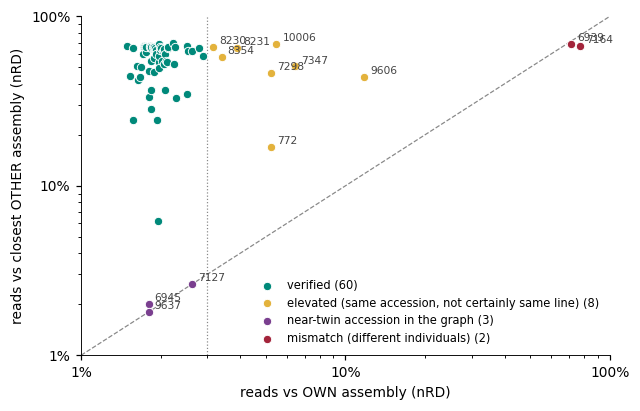

ecotype      tier  reads_vs_own best_other_name  reads_vs_best_other  reads_vs_grenenet  assembly_vs_grenenet
   8230  elevated           3.2           Tur-4                 66.3                1.6                   2.9
   8354  elevated           3.4           Kas-1                 57.8                1.5                   4.9
   8231  elevated           3.9          Sten-0                 65.1                3.0                   3.2
   7298  elevated           5.2            Bs-1                 46.4                1.2                   6.4
    772  elevated           5.2        Shahdara                 16.9                1.1                   3.3
  10006  elevated           5.5         Valsi-1                 68.6                7.1                   8.4
   7347  elevated           6.4            Ct-1                 50.6                1.0                   6.0
   9606  elevated          11.8         Toufl-1                 43.7                8.2                  10.3
   6939  m

In [2]:
TIER = {"verified": "#00897A", "elevated": "#E3B23C", "near_twin": "#7A3F8F", "mismatch": "#A3243B"}
TLAB = {"verified": "verified", "elevated": "elevated (same accession, not certainly same line)",
        "near_twin": "near-twin accession in the graph", "mismatch": "mismatch (different individuals)"}
fig, ax = plt.subplots(figsize=(6.2, 4))
for t in TIER:
    d = ID[ID.tier == t]
    ax.scatter(d.reads_vs_own, d.reads_vs_best_other, s=30, color=TIER[t], linewidths=0.6,
               edgecolors="white", label=f"{TLAB[t]} ({len(d)})", zorder=3)
    for _, r in d[d.tier != "verified"].iterrows():
        ax.annotate(r.ecotype, (r.reads_vs_own, r.reads_vs_best_other), xytext=(4, 2),
                    textcoords="offset points", fontsize=7, color="#444")
lim = [0.01, 1]
ax.plot(lim, lim, ls="--", lw=0.8, color="#888")
ax.axvline(0.03, ls=":", lw=0.8, color="#888")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("reads vs OWN assembly (nRD)"); ax.set_ylabel("reads vs closest OTHER assembly (nRD)")
ax.legend(frameon=False, fontsize=7.5, loc="lower right")
panel(ax, "", "each dot = one founder · above the diagonal = own assembly matches best")
plt.savefig(f"{PLOTS}/q1_founder_identity.png", dpi=150, bbox_inches="tight"); plt.show()
print((ID[ID.tier != "verified"][["ecotype", "tier", "reads_vs_own", "best_other_name", "reads_vs_best_other",
                                 "reads_vs_grenenet", "assembly_vs_grenenet"]]
       .assign(**{c: lambda d, c=c: (100 * d[c]).round(1) for c in ["reads_vs_own", "reads_vs_best_other",
                                                                     "reads_vs_grenenet", "assembly_vs_grenenet"]})
       .to_string(index=False)))

## Q1 · What PanGenie recovers of a founder's variation — with the analysis filter

**Design.** For each assembly founder that also has public short reads, the founder's
assembly is **removed from the graph** (alleles no other assembly carries are trimmed), the
graph is re-indexed, and the founder is genotyped from its short reads — exactly the situation
of the 153 short-read founders, whose haplotypes are in no graph. Its own assembly is the
truth. (`panel/pangenie_genotyping/scripts/pangenie_trueloo_one.sh`,
`score_loo_arch3.py`.)

The earlier "leave-one-out" run genotyped the same reads against the full 135-assembly graph,
**which contains the founder's own assembly**; PanGenie then recovers the founder's own
haplotype (86% of 10002's assembly-private Chr1 alleles were called 1/1). It is shown here
only as the comparison that measures how optimistic that was.

Every variant the assembly carries ends in exactly one of three fates:

- **recovered** — PanGenie calls it.
- **called REF** — PanGenie genotypes the site but says the founder does not carry it. A real
  error: downstream it counts as "not a carrier" and pulls the allele frequency down.
- **missed** — PanGenie gives no usable genotype. Three causes, merged in the plot and listed
  separately in the table: *no call* (missing after QC), *bubble skipped by PanGenie* (its
  graph builder drops bubbles containing an undefined base or within 2 k-mers of a chromosome
  end), *not in the graph* (no other assembly carries it, so no graph genotyper can call it).
  A missed genotype only costs precision downstream: kMate drops the founder from that
  variant's denominator instead of counting it as REF.

All bars are **pooled over the verified founders** (counts summed, then divided).

The other half is what PanGenie **invents**: a **false call** is a variant PanGenie calls in
the founder where its own assembly has the reference allele. Below zero, the first number is
false calls as a % of the founder's **true** variants (same scale as the bars: per 100 true
variants, this many invented); the number in brackets is false calls as a % of **all of
PanGenie's calls** (1 − precision). Per 100 true large SVs: 62 recovered + 8 false = 70 calls,
and 8 / 70 = 11%. Panels
B and C show **recall** (what it finds of what the founder truly carries) and **precision**
(how many of its calls are correct) for each founder separately (line = median). nRD is in the
table below the figure.

The second figure asks whether a different **GQ threshold** would do better than
production's GQ ≥ 20: precision (A) and recall (B) at every threshold from no GQ filter to
PanGenie's maximum (its GQ jumps from ~200 straight to the 10 000 cap), production marked by
the dashed line; C and D show how many of PanGenie's calls each threshold removes, as a share
and as a number per founder.

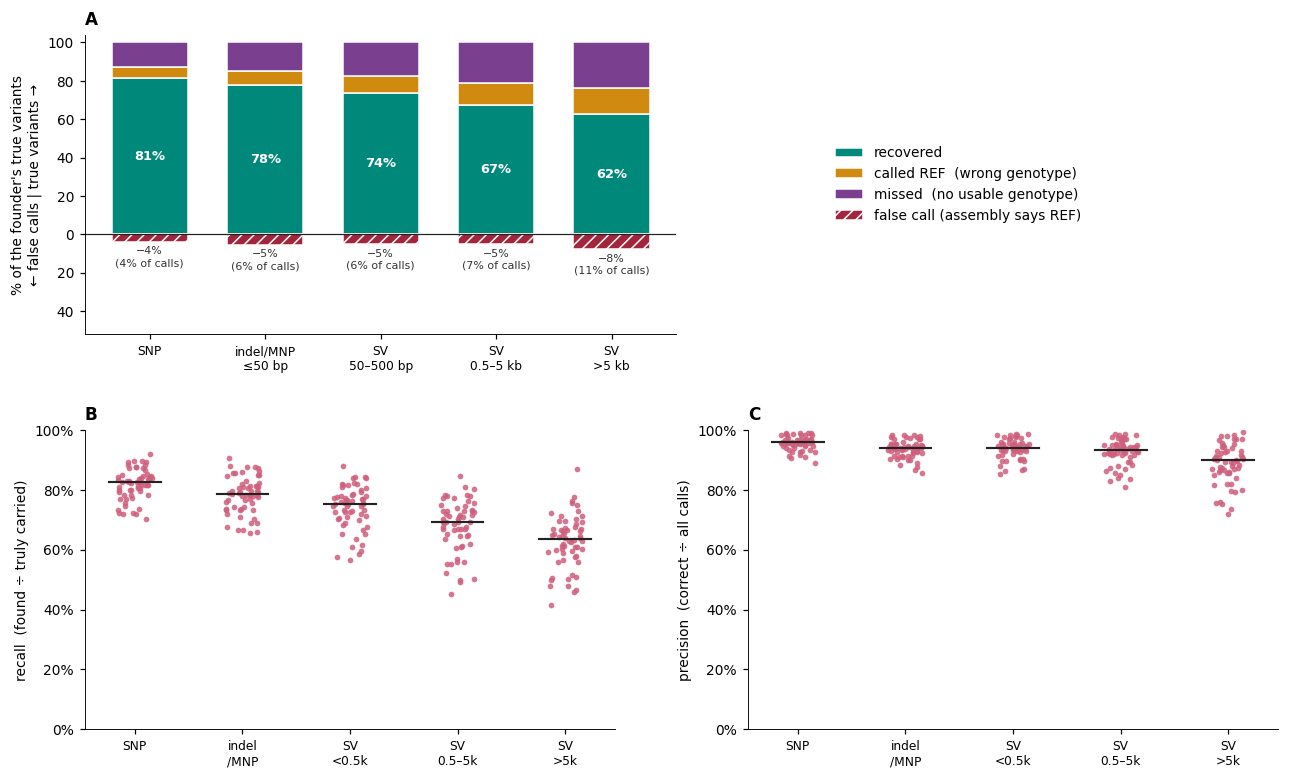

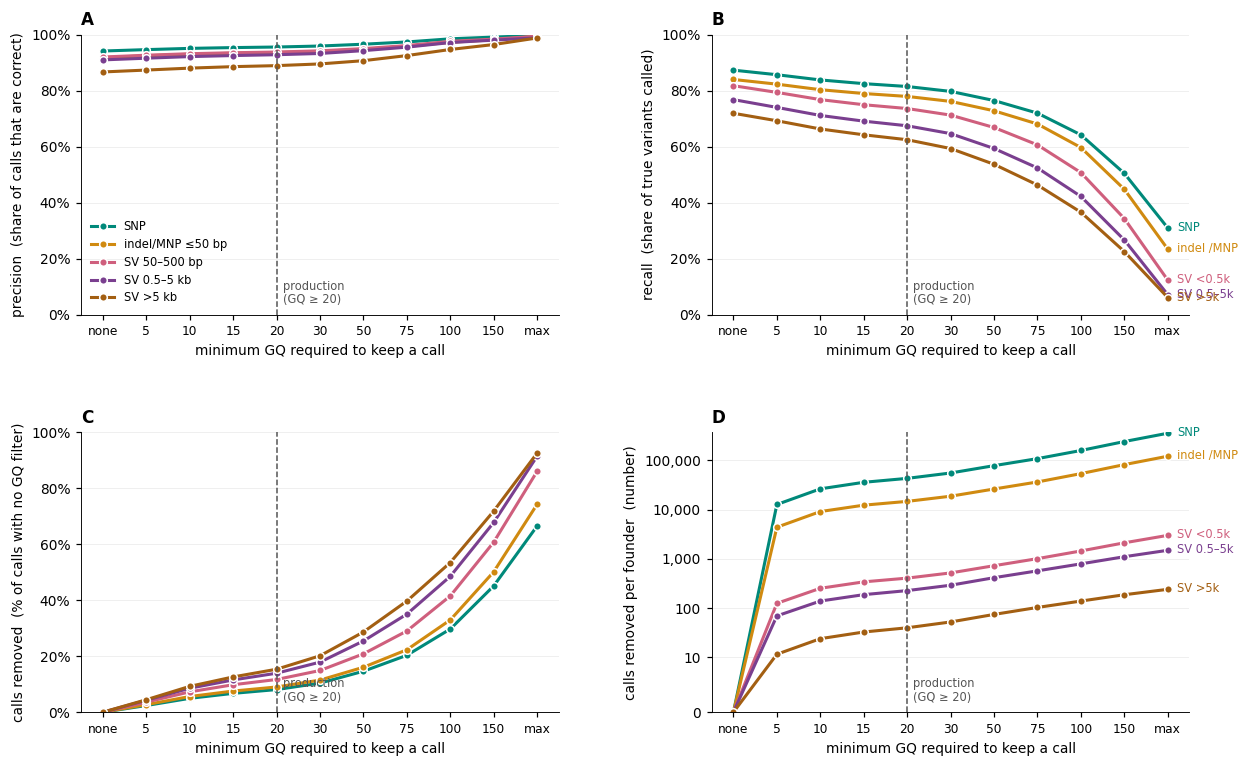

founder removed from the graph, production QC, analysis filter, pooled over 60 verified founders

                                                 SNP  indel/MNP ≤50 bp  SV 50–500 bp  SV 0.5–5 kb  SV >5 kb
recall                                         81.46             77.92         73.59        67.43     62.45
precision                                      95.56             93.59         93.78        92.81     88.92
nRD                                            10.47             14.03         15.56        19.75     25.75
% of PanGenie calls that are false              4.44              6.41          6.22         7.19     11.08
false calls per 100 true variants               3.78              5.34          4.89         5.22      7.78
% recovered                                    81.46             77.92         73.59        67.43     62.45
% called REF  (wrong genotype)                  5.75              7.38          8.68        11.37     13.87
% missed  (no usable genotype)        

In [3]:
def pooled(S, stage="prod"):
    g = S[S.stage == stage].groupby("size_class").sum(numeric_only=True).reindex(CLS)
    g["missed"] = g[MISSED].sum(axis=1)
    g["recall"] = g.recovered / g.truth_carriers
    g["precision"] = g.recovered / (g.recovered + g.fp)
    g["nRD"] = g.nonref_disc / g.nonref
    return g
def per_founder(S, stage="prod"):
    g = S[S.stage == stage].groupby(["ecotype", "size_class"]).sum(numeric_only=True)
    return pd.DataFrame(dict(recall=g.recovered / g.truth_carriers, nRD=g.nonref_disc / g.nonref,
                             precision=g.recovered / (g.recovered + g.fp))).reset_index()

G = pooled(S_lo)
fig = plt.figure(figsize=(14, 8.2))
outer = fig.add_gridspec(2, 1, hspace=0.32)
top = outer[0].subgridspec(1, 2, width_ratios=[1.3, 1], wspace=0.28)
bot = outer[1].subgridspec(1, 2, wspace=0.25)
# ax: 0 fates (A) · 1 recall (B) · 2 precision (C) · 3 legend slot for A
ax = [fig.add_subplot(top[0]), fig.add_subplot(bot[0]), fig.add_subplot(bot[1]), fig.add_subplot(top[1])]
ax[3].axis("off")
xx = np.arange(len(CLS)); bottom = np.zeros(len(CLS))
for f in FATE:
    v = 100 * G[f] / G.truth_carriers
    ax[0].bar(xx, v, 0.66, bottom=bottom, color=FATE[f], label=FATELAB[f],
              edgecolor="white", linewidth=1)
    bottom += v.values
fp = 100 * G.fp / G.truth_carriers                     # false calls, on the same scale
ax[0].bar(xx, -fp, 0.66, color=FALSE, hatch="///", edgecolor="white", linewidth=1,
          label="false call (assembly says REF)")
ax[0].axhline(0, color="#222", lw=0.8)
for i, (r, p, f_) in enumerate(zip(G.recall, G.precision, fp)):
    ax[0].annotate(f"{100*r:.0f}%", (i, 100*r/2), ha="center", va="center", color="white",
                   fontsize=8.5, fontweight="bold")
    ax[0].annotate(f"−{f_:.0f}%\n({100*(1-p):.0f}% of calls)", (i, -f_), xytext=(0, -3),
                   textcoords="offset points", ha="center", va="top", fontsize=7.2, color="#333")
ax[0].set_xticks(xx); ax[0].set_xticklabels([CLSLAB[c] for c in CLS], fontsize=8)
ax[0].set_ylim(-52, 104); ax[0].set_yticks(range(-40, 101, 20))
ax[0].set_yticklabels([f"{abs(v)}" for v in range(-40, 101, 20)])
ax[0].set_ylabel("% of the founder's true variants\n← false calls | true variants →")
h_, l_ = ax[0].get_legend_handles_labels()
ax[3].legend(h_, l_, frameon=False, fontsize=9, loc="center left")
panel(ax[0], "A", f"founder removed from the graph · production QC · {FLAB}")

A_lo = per_founder(S_lo)
rng_ = np.random.default_rng(0)
for k, metric, lab, letter in [(1, "recall", "recall  (found ÷ truly carried)", "B"),
                               (2, "precision", "precision  (correct ÷ all calls)", "C")]:
    a = ax[k]
    for i, c in enumerate(CLS):
        v = A_lo[A_lo.size_class == c][metric].values
        a.scatter(np.full(len(v), i) + rng_.uniform(-.16, .16, len(v)), v, s=14, color=GRP["trueloo"],
                  zorder=3, linewidths=0, alpha=0.85)
        a.plot([i - 0.24, i + 0.24], [np.median(v)] * 2, color="#222", lw=1.4, zorder=4)
    a.set_xticks(xx); a.set_xticklabels([CLSSHORT[c] for c in CLS], fontsize=8)
    a.yaxis.set_major_formatter(PercentFormatter(1.0)); a.set_ylabel(lab)
    panel(a, letter, f"each dot = one founder ({len(LOO)}) · line = median")
ax[1].set_ylim(0, 1); ax[2].set_ylim(0, 1)
# D: can a stricter GQ remove the false calls? (hom-alt calls surviving production QC)
FC = pd.concat([pd.read_csv(f, dtype={"size_class": str}).assign(ecotype=os.path.basename(f).split(".")[0])
                for f in glob.glob(f"{QC}/false_calls/*.csv.gz")], ignore_index=True)
FC = FC[FC.ecotype.isin(LOO) & (FC.baseline if FILTER == "baseline" else True)]
if MATCH == "events":                                   # SV calls as events (one row per called event)
    ev = EVRAW["trueloo"]; ev = ev[ev.called_any & ev.ecotype.isin(LOO) & (ev.baseline if FILTER == "baseline" else True)]
    FC = pd.concat([FC[~FC.size_class.str.startswith("sv")],
                    pd.DataFrame(dict(size_class=ev.size_class, truth=ev.truth.astype(int), gq=ev.gq_any, ecotype=ev.ecotype))],
                   ignore_index=True)
# full GQ curve: hom-alt calls at ANY GQ (GQ missing = fails every threshold but "none")
THR = [(None, "none"), (5, "5"), (10, "10"), (15, "15"), (20, "20"), (30, "30"), (50, "50"), (75, "75"),
       (100, "100"), (150, "150"), (10000, "max")]          # PanGenie GQ jumps from ~200 to its 10000 cap
CURVE = {"SNP": "#00897A", "small": "#D08A10", "sv_50_500": "#CF5F7D", "sv_500_5k": "#7A3F8F", "sv_5k": "#A35F12"}
plt.savefig(f"{PLOTS}/q1_recovery{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

# separate figure: what each GQ threshold buys (precision) and costs (recall)
rows = []
for c in CLS:
    x = FC[FC.size_class == c]; n_truth = G.loc[c, "truth_carriers"]
    for t, lab in THR:
        k = x if t is None else x[x.gq >= t]
        tp = (k.truth == 1).sum()
        rows.append(dict(size_class=c, gq=lab, recall=tp / n_truth, precision=tp / max(len(k), 1), calls=len(k)))
GQT = pd.DataFrame(rows)
n0 = GQT[GQT.gq == "none"].set_index("size_class").calls
GQT["lost_pct"] = 1 - GQT.calls / GQT.size_class.map(n0)                  # share of calls removed vs no GQ filter
GQT["lost_per_founder"] = (GQT.size_class.map(n0) - GQT.calls) / len(LOO)  # calls removed, per founder
xs = np.arange(len(THR)); i20 = [l for _, l in THR].index("20")
fig, ax2 = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw=dict(wspace=0.32, hspace=0.42))
ax2 = ax2.ravel()
for a, metric, lab in [(ax2[0], "precision", "precision  (share of calls that are correct)"),
                       (ax2[1], "recall", "recall  (share of true variants called)"),
                       (ax2[2], "lost_pct", "calls removed  (% of calls with no GQ filter)"),
                       (ax2[3], "lost_per_founder", "calls removed per founder  (number)")]:
    for c in CLS:
        v = GQT[GQT.size_class == c].set_index("gq").reindex([l for _, l in THR])[metric].values
        a.plot(xs, v, "-o", color=CURVE[c], lw=2, ms=5, mec="white", mew=1, label=CLSLAB[c].replace("\n", " "))
        if metric in ("recall", "lost_per_founder"):   # end labels only where the lines are apart
            a.annotate(CLSSHORT[c].replace("\n", " "), (xs[-1], v[-1]), xytext=(6, 0), textcoords="offset points",
                       va="center", fontsize=7.5, color=CURVE[c])
    a.axvline(i20, ls="--", lw=1, color="#555")
    a.annotate("production\n(GQ ≥ 20)", (i20, 0.04), xycoords=("data", "axes fraction"), xytext=(4, 0),
               textcoords="offset points", fontsize=7.5, color="#555")
    a.set_xticks(xs); a.set_xticklabels(["none"] + [l for _, l in THR[1:]], fontsize=8)
    a.set_xlabel("minimum GQ required to keep a call"); a.set_ylabel(lab)
    if metric == "lost_per_founder":
        a.set_yscale("symlog", linthresh=10); a.set_ylim(0, None)
        a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    else:
        a.set_ylim(0, 1); a.yaxis.set_major_formatter(PercentFormatter(1.0))
    a.grid(axis="y", color="#eee", lw=0.6); a.set_axisbelow(True)
panel(ax2[0], "A", "stricter →  fewer false calls"); panel(ax2[1], "B", "stricter →  more true variants lost")
panel(ax2[2], "C", "share of PanGenie calls the threshold removes")
panel(ax2[3], "D", f"same, as a number of calls per founder (mean over {len(LOO)})")
ax2[0].legend(frameon=False, fontsize=7.5, loc="lower left")
plt.savefig(f"{PLOTS}/q1_gq_threshold{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

T = (100 * G[["recall", "precision", "nRD"]]).round(2)
T["% of PanGenie calls that are false"] = (100 * (1 - G.precision)).round(2)
T["false calls per 100 true variants"] = (100 * G.fp / G.truth_carriers).round(2)
for f in list(FATE) + MISSED:
    T[f"% {FATELAB[f]}" if f not in MISSED else f"   of which: {FATELAB[f]}"] = (100 * G[f] / G.truth_carriers).round(2)
T["truth variants"] = G.truth_carriers.astype(int)
T.index = [CLSLAB[c].replace("\n", " ") for c in CLS]
print(f"founder removed from the graph, production QC, {FLAB}, pooled over {len(LOO)} verified founders\n")
print(T.T.to_string())
M = per_founder(S_lo).groupby("size_class")[["recall", "precision", "nRD"]].median()
print("\nmedian over founders, production QC (%)\n"); print((100 * M.reindex(CLS)).round(2).to_string())
print("\nGQ threshold sweep, founder removed (%): precision, then recall")
TD = GQT.assign(recall=lambda d: (100 * d.recall).round(1), precision=lambda d: (100 * d.precision).round(1))
for m in ("precision", "recall"):
    print(f"\n{m}"); print(TD.pivot(index="size_class", columns="gq", values=m).reindex(index=CLS, columns=[l for _, l in THR]).to_string())
print("\ncalls removed vs no GQ filter (%)")
print((100 * GQT.pivot(index="size_class", columns="gq", values="lost_pct")).round(1).reindex(index=CLS, columns=[l for _, l in THR]).to_string())
print(f"\ncalls removed vs no GQ filter, per founder (mean over {len(LOO)})")
print(GQT.pivot(index="size_class", columns="gq", values="lost_per_founder").round(0).astype(int)
      .reindex(index=CLS, columns=[l for _, l in THR]).to_string())
print("\ncalls kept with no GQ filter, per founder (mean):", (n0 / len(LOO)).round(0).astype(int).reindex(CLS).to_dict())
if MATCH == "exact":
    mech = FC[FC.truth == 0].groupby("size_class").bubble_nonref.mean().reindex(CLS)
    print("\nfalse calls in a bubble where the founder carries a different variant (substitution) (%)")
    print((100 * mech).round(1).to_string())
SS = pooled(S_lo_all[S_lo_all.ecotype.isin(SENS)])
print(f"\nsensitivity — verified + elevated ({S_lo_all[S_lo_all.ecotype.isin(SENS)].ecotype.nunique()} founders) "
      f"vs verified ({len(LOO)}), production QC (%)")
print(pd.concat({"verified": 100 * G[["recall", "precision"]], "verified+elevated": 100 * SS[["recall", "precision"]]},
                axis=1).round(2).to_string())
R = pooled(S_lo, "raw")
print("\nraw PanGenie output (no QC), founder removed: recall / nRD (%)"
      + (" — SNP/indel only; SV events are scored at production QC only" if MATCH == "events" else ""))
print((100 * R[["recall", "nRD"]]).round(2).T.dropna(axis=1).to_string())

**Reading it.** _(filled in once the numbers are reviewed)_

### How the downstream variant filters change the metrics

The analyses do not use every panel record. **Every analysis** drops **private** variants
(carried by a single founder) and keeps call rate ≥ 50% across the 231 founders — the
**baseline** below. Some analyses are stricter: MAC ≥ 12 (`lib.COMMON_MAC`, MAF ≥ 5%) and/or
call rate ≥ 90%. Both are properties of the
production record, not of the founder being scored, so the benchmark calls are kept or dropped
exactly as the analyses would (`panel_record_stats.py`, `score_filters.py`; in the
similar-allele version, SV filters are applied per event with the event's union carriers and
union call rate, as `_build_event_units.py` defines them). A variant outside the production
panel fails every filter.

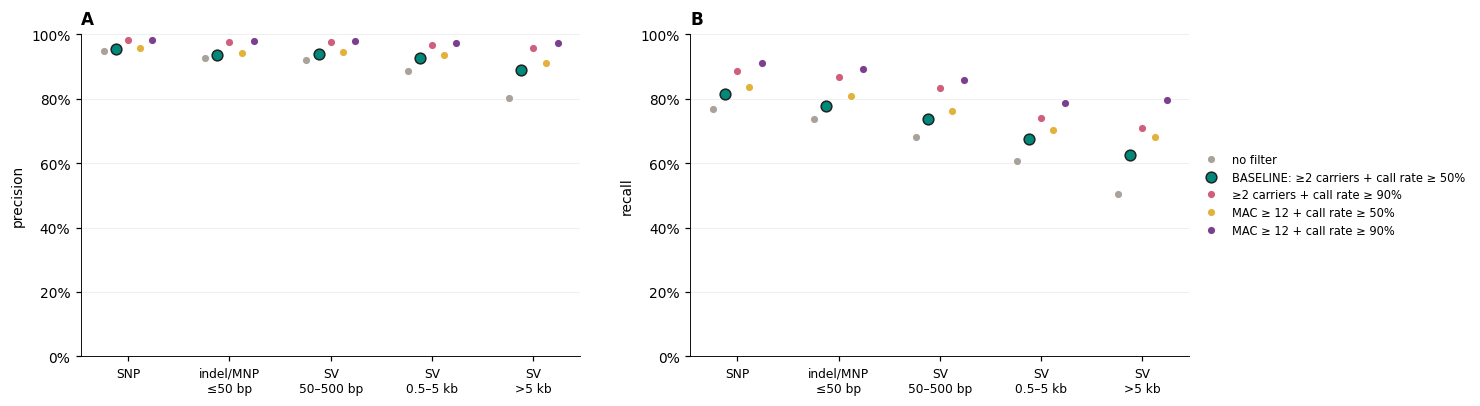

precision / recall (%) under the downstream filters, verified founders, founder removed

size_class                                SNP  small  sv_50_500  sv_500_5k  sv_5k
no filter                                94.9   92.8       92.2       88.6   80.3
BASELINE: ≥2 carriers + call rate ≥ 50%  95.6   93.6       93.8       92.8   88.9
≥2 carriers + call rate ≥ 90%            98.2   97.6       97.6       96.7   95.7
MAC ≥ 12 + call rate ≥ 50%               95.8   94.3       94.4       93.5   91.2
MAC ≥ 12 + call rate ≥ 90%               98.4   97.9       97.9       97.2   97.2

size_class                                SNP  small  sv_50_500  sv_500_5k  sv_5k
no filter                                76.8   73.9       68.0       60.7   50.4
BASELINE: ≥2 carriers + call rate ≥ 50%  81.5   77.9       73.6       67.4   62.5
≥2 carriers + call rate ≥ 90%            88.6   86.6       83.4       74.0   71.1
MAC ≥ 12 + call rate ≥ 50%               83.6   80.9       76.2       70.3   68.1
MAC ≥ 12

In [4]:
COMBOS = [("all", "none", "no filter"),
          ("non-private (>=2)", ">=0.5", "BASELINE: ≥2 carriers + call rate ≥ 50%"),   # every analysis
          ("non-private (>=2)", ">=0.9", "≥2 carriers + call rate ≥ 90%"),              # stricter options
          ("common (MAC>=12)", ">=0.5", "MAC ≥ 12 + call rate ≥ 50%"),
          ("common (MAC>=12)", ">=0.9", "MAC ≥ 12 + call rate ≥ 90%")]
FI = pd.concat([pd.read_csv(f, dtype={"ecotype": str}) for f in glob.glob(f"{QC}/filters/trueloo_*.csv")], ignore_index=True)
FI = FI[FI.ecotype.isin(LOO)]
if MATCH == "events":                         # SVs: event-level union carriers / call rate
    ev = EVRAW["trueloo"]; ev = ev[ev.ecotype.isin(LOO) & (ev.truth | ev.called)].copy()
    inp = ev.n_carriers.notna(); nc, nl = ev.n_carriers.fillna(0), ev.n_called.fillna(0)
    MAC = {"all": pd.Series(True, index=ev.index), "non-private (>=2)": inp & (nc >= 2),
           "common (MAC>=12)": inp & (nc >= 12) & (nc <= 231 - 12)}
    CRT = {"none": pd.Series(True, index=ev.index), ">=0.5": inp & (nl >= 0.5 * 231), ">=0.9": inp & (nl >= 0.9 * 231)}
    rows_ = []
    for mn, mm in MAC.items():
        for cn, cm in CRT.items():
            k = ev[mm & cm]
            g = k.groupby(["ecotype", "size_class"])
            r = pd.DataFrame(dict(truth_carriers=g.truth.sum(), recovered=g.apply(lambda x: (x.truth & x.called).sum()),
                                  fp=g.apply(lambda x: (x.called & ~x.truth).sum()))).reset_index()
            rows_.append(r.assign(carriers=mn, call_rate=cn))
    FI = pd.concat([FI[~FI.size_class.str.startswith("sv")], pd.concat(rows_)], ignore_index=True)
P_ = FI.groupby(["carriers", "call_rate", "size_class"])[["truth_carriers", "recovered", "fp"]].sum()
P_["precision"] = P_.recovered / (P_.recovered + P_.fp); P_["recall"] = P_.recovered / P_.truth_carriers
FCOL = ["#A8A29A", "#00897A", "#CF5F7D", "#E3B23C", "#7A3F8F"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(wspace=0.22))
for a, metric in zip(ax, ["precision", "recall"]):
    for j, (mn, cn, lab) in enumerate(COMBOS):
        v = [P_.loc[(mn, cn, c), metric] if (mn, cn, c) in P_.index else np.nan for c in CLS]
        a.plot(np.arange(len(CLS)) + (j - 2) * 0.12, v, "o", color=FCOL[j], ms=7 if j == 1 else 5.5,
               mec="#222" if j == 1 else "white", mew=1.0 if j == 1 else 0.8, label=lab)
    a.set_xticks(range(len(CLS))); a.set_xticklabels([CLSLAB[c] for c in CLS], fontsize=8)
    a.set_ylim(0, 1); a.yaxis.set_major_formatter(PercentFormatter(1.0)); a.set_ylabel(metric)
    a.grid(axis="y", color="#eee", lw=0.6); a.set_axisbelow(True)
panel(ax[0], "A", "founder removed · production QC"); panel(ax[1], "B", "")
ax[1].legend(frameon=False, fontsize=7.5, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.savefig(f"{PLOTS}/q1_filters.png", dpi=150, bbox_inches="tight"); plt.show()
TF = pd.concat({lab: (100 * P_.loc[(mn, cn)][["precision", "recall"]]).round(1).reindex(CLS)
                for mn, cn, lab in COMBOS}, axis=1)
print("precision / recall (%) under the downstream filters, verified founders, founder removed\n")
print(TF.xs("precision", axis=1, level=1).T.to_string()); print()
print(TF.xs("recall", axis=1, level=1).T.to_string())
NT = P_.truth_carriers.unstack("size_class")[CLS]
print("\ntruth variants kept by each filter (% of unfiltered)")
print((100 * NT / NT.loc[("all", "none")]).round(1).loc[[(m, c) for m, c, _ in COMBOS]].to_string())

### Where are the false SV calls — and which mask would raise precision?

Called SV events (founder removed, production QC, verified founders) split by genomic and
graph context (`precision_by_context.py`): distance to the centromere (TAIR10 midpoints, as
downstream), TE density (TAIR10 TEs within ±5 kb), and how many alleles the graph bubble holds.
Precision is the priority — a dropped call is an accepted cost, a wrong one is not — so each
candidate mask is scored as the precision of the calls it **keeps** against the share of
**true** calls it throws away.

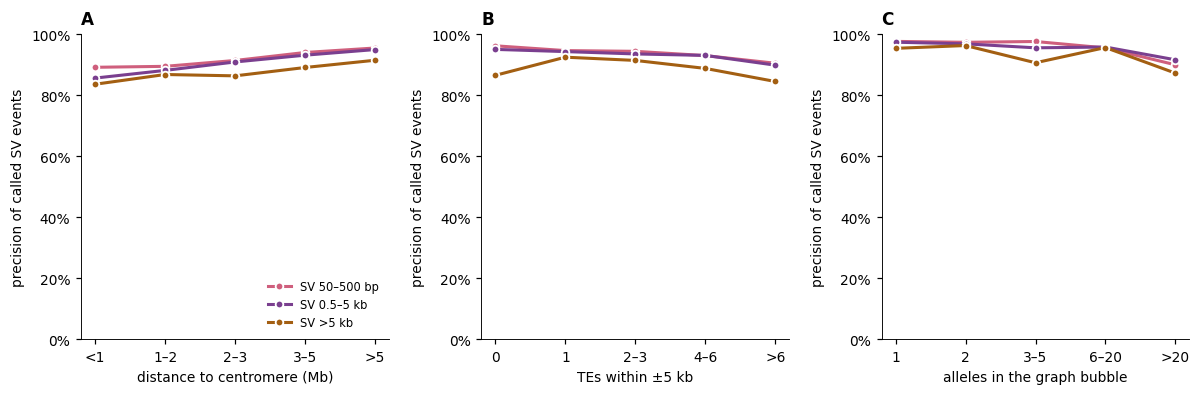

each mask: precision of the SV calls it keeps / % of TRUE SV calls it drops

size_class           sv_50_500  sv_500_5k  sv_5k  sv_50_500 lost  sv_500_5k lost  sv_5k lost
mask                                                                                        
none (production)         93.8       92.8   88.9             0.0             0.0         0.0
centromere ±1 Mb          94.0       93.1   89.2             4.6             3.8         4.2
centromere ±2 Mb          94.5       93.7   89.7            14.0            13.7        21.0
centromere ±3 Mb          95.1       94.4   90.6            26.2            29.2        37.5
>3 TEs within ±5 kb       95.1       94.1   91.0            40.7            52.8        50.0
>6 TEs within ±5 kb       94.5       93.7   90.2            17.4            22.5        20.9
bubble >5 alleles         97.6       96.3   93.5            70.7            89.8        91.9
bubble >20 alleles        96.5       96.0   94.9            40.3            71.9      

In [5]:
sys_path = __import__("sys").path
if QC not in sys_path: sys_path.insert(0, QC)
from precision_by_context import te_density, CEN
X = EVRAW["trueloo"]; X = X[X.called & X.ecotype.isin(LOO) & (X.baseline if FILTER == "baseline" else True)].reset_index(drop=True)
X["cen_mb"] = (X.pos - X.chrom.map(CEN)).abs() / 1e6
X["te"] = te_density(X)
SVC = ["sv_50_500", "sv_500_5k", "sv_5k"]
CTX = [("cen_mb", [0, 1, 2, 3, 5, 100], ["<1", "1–2", "2–3", "3–5", ">5"], "distance to centromere (Mb)"),
       ("te", [-1, 0, 1, 3, 6, 1000], ["0", "1", "2–3", "4–6", ">6"], "TEs within ±5 kb"),
       ("n_alleles", [0, 1, 2, 5, 20, 10000], ["1", "2", "3–5", "6–20", ">20"], "alleles in the graph bubble")]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(wspace=0.3))
for a, (col, bins, labs, xl) in zip(ax, CTX):
    b = pd.cut(X[col], bins, labels=labs)
    for c in SVC:
        g = X[X.size_class == c].groupby(b[X.size_class == c], observed=False).truth
        p, n = g.mean().reindex(labs), g.size().reindex(labs)
        a.plot(range(len(labs)), p.values, "-o", color=CURVE[c], lw=2, ms=5, mec="white", mew=1.2,
               label=CLSLAB[c].replace("\n", " "))
    a.set_xticks(range(len(labs))); a.set_xticklabels(labs); a.set_xlabel(xl)
    a.yaxis.set_major_formatter(PercentFormatter(1.0)); a.set_ylim(0, 1.0); a.set_ylabel("precision of called SV events")
for a, l in zip(ax, "ABC"):
    panel(a, l, "")
ax[0].legend(frameon=False, fontsize=7.5, loc="lower right")
plt.savefig(f"{PLOTS}/q1_precision_context{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

masks = {"none (production)": pd.Series(False, index=X.index), "centromere ±1 Mb": X.cen_mb < 1,
         "centromere ±2 Mb": X.cen_mb < 2, "centromere ±3 Mb": X.cen_mb < 3,
         ">3 TEs within ±5 kb": X.te > 3, ">6 TEs within ±5 kb": X.te > 6,
         "bubble >5 alleles": X.n_alleles > 5, "bubble >20 alleles": X.n_alleles > 20, "GQ < 100": X.gq < 100}
rows = []
for name, m in masks.items():
    for c in SVC:
        s_ = (X.size_class == c).values; keep, drop = s_ & ~m.values, s_ & m.values
        rows.append(dict(mask=name, size_class=c, precision=100 * X.truth[keep].mean(),
                         true_lost=100 * X.truth[drop].sum() / max(X.truth[s_].sum(), 1)))
MT = pd.DataFrame(rows)
print("each mask: precision of the SV calls it keeps / % of TRUE SV calls it drops\n")
print(MT.pivot(index="mask", columns="size_class", values="precision").reindex(index=list(masks), columns=SVC).round(1)
      .join(MT.pivot(index="mask", columns="size_class", values="true_lost").reindex(columns=SVC).round(1), rsuffix=" lost")
      .to_string())

**Reading it.** _(filled in once the numbers are reviewed)_

### The same effect across all founders — SNPs against the GrENE-Net panel

Figure 1 rests on the founders with a true leave-one-out run. The old GrENE-Net SNP panel lets
the question be asked of **every** founder: the same PanGenie calls scored against the same
independent SNP genotypes (`grenenet_concordance_by_group.py`; biallelic SNP sites, alleles
checked, production QC).

- **own assembly in the graph** — the verified assembly founders, old run
- **founder removed** — the same founders, true leave-one-out
- **production short-read founders** — the 151 founders PanGenie genotypes for the panel;
  their haplotypes are in no graph (5772 and 9947, the two assembly founders whose
  short-read genotypes production uses, were genotyped against the full graph and are left
  out)

If having your own haplotype in the graph is what made the old run look good, the true
leave-one-out founders should fall with the production founders, not with the old run.
Panel A uses the analysis filter: only GrENE-Net SNP sites whose production record the
analyses keep (≥ 2 carriers, call rate ≥ 50%). Panel B cannot be filtered — it is about
old-panel SNPs that have no record in the new panel at all.

Panel B asks the complementary question: **variation the graph never contains.** PanGenie
only genotypes alleles some assembly already carries. For each founder, the share of its
own minor-allele SNPs in the old panel that no assembly carries: for an assembly founder
this can only be old-panel error (its haplotype is in the graph), so the assembly founders
set the floor; the excess in the short-read founders is their own variation that no graph
genotyper can recover.

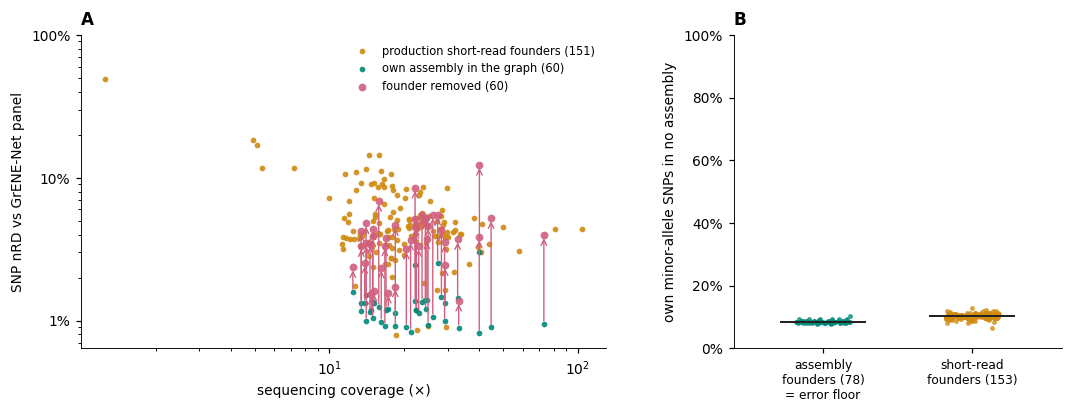

SNP nRD vs GrENE-Net, production QC — median (%) by group
group
own assembly in the graph (60)          1.27
founder removed (60)                    4.27
production short-read founders (151)    4.47

paired, same founders: own assembly in graph -> removed (%)
group  ingraph  trueloo
acc                    
10002     1.13     3.31
159       1.45     4.33
5784      2.53     5.51
5811      1.43     3.71
6150      0.89     1.38
6184      0.82     3.84
6244      0.84     3.67
6898      1.17     3.31
6911      3.03    12.29
6915      0.91     1.73
6929      1.21     1.57
6932      0.90     5.21
6938      1.39     3.75
6958      1.18     4.66
6963      1.33     2.53
6979      1.18     4.44
7000      1.00     3.48
7002      0.95     3.97
7003      0.99     2.35
7025      1.24     6.86
7063      2.45     8.50
7092      0.92     3.35
7143      0.99     3.55
7186      1.37     5.16
7217      1.18     3.80
7255      1.51     4.79
7288      0.93     4.61
7316      1.35     3.89
7323      1.20     5

In [6]:
GN = pd.read_csv(f"{QC}/grenenet_concordance_by_group.csv", dtype={"acc": str})
GN = GN[(GN.stage == "gq") & (GN["filter"] == FILTER)]
st = pd.read_csv(f"{P}/preprocess_qc/output/stage_aggregate.tsv", sep="\t", dtype={"ecotype": str})
cov = st.drop_duplicates("ecotype").set_index("ecotype").cov_est
GN["cov"] = GN.acc.map(cov)
GN.loc[GN.group == "loo", "group"] = "ingraph"; GN.loc[GN.group == "main", "group"] = "unseen"
GN = GN[~((GN.group == "ingraph") & GN.acc.isin(["5772", "9947"]))]
GN = GN[(GN.group == "unseen") | GN.acc.isin(VER)]          # assembly founders: verified only
GLAB = {"ingraph": f"own assembly in the graph ({(GN.group=='ingraph').sum()})",
        "trueloo": f"founder removed ({(GN.group=='trueloo').sum()})",
        "unseen": "production short-read founders (151)"}

O = pd.read_csv(f"{QC}/old_only_snps_per_founder.csv", dtype={"founder": str})
O["frac"] = O.n_old_only_not_in_graph / O.filter(like="n_").sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.3))
for g in ["unseen", "ingraph", "trueloo"]:
    d = GN[GN.group == g]
    ax[0].scatter(d["cov"], d.nRD, s=26 if g == "trueloo" else 14, color=GRP[g], linewidths=0,
                  alpha=0.9, label=GLAB[g], zorder=4 if g == "trueloo" else 3)
pair = GN[GN.group.isin(["ingraph", "trueloo"])].pivot(index="acc", columns="group", values="nRD").dropna()
for a, r in pair.iterrows():
    ax[0].annotate("", xy=(cov.get(a), r.trueloo), xytext=(cov.get(a), r.ingraph),
                   arrowprops=dict(arrowstyle="->", color="#CF5F7D", lw=0.9))
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_ylim(None, 1)   # log axis: up to 100%
ax[0].set_xlabel("sequencing coverage (×)"); ax[0].set_ylabel("SNP nRD vs GrENE-Net panel")
ax[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax[0].legend(frameon=False, fontsize=7.5, loc="upper right")
panel(ax[0], "A", f"each dot = one founder · production QC · {FLAB}")

rng = np.random.default_rng(0)
for i, s in enumerate(["cactus", "pangenie"]):
    v = O[O.source == s].frac.values
    ax[1].scatter(np.full(len(v), i) + rng.uniform(-.18, .18, len(v)), v, s=10, color=SRC[s],
                  linewidths=0, alpha=0.8)
    ax[1].plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color="#222", lw=1.3)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["assembly\nfounders (78)\n= error floor",
                                                 "short-read\nfounders (153)"], fontsize=8)
ax[1].yaxis.set_major_formatter(PercentFormatter(1.0)); ax[1].set_xlim(-0.6, 1.6); ax[1].set_ylim(0, 1)
ax[1].set_ylabel("own minor-allele SNPs in no assembly")
panel(ax[1], "B", "variation the graph never sees")
plt.savefig(f"{PLOTS}/q1_all_founders{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

print("SNP nRD vs GrENE-Net, production QC — median (%) by group")
print((100 * GN.groupby("group").nRD.median()).round(2).rename(GLAB).to_string())
if len(pair):
    print("\npaired, same founders: own assembly in graph -> removed (%)")
    print((100 * pair[["ingraph", "trueloo"]]).round(2).to_string())
print("\nshare of own minor-allele SNPs in no assembly (%)")
q = O.groupby("source").frac.describe()[["count", "25%", "50%", "75%"]]
q[["25%", "50%", "75%"]] *= 100
print(q.round(2).astype({"count": int}).to_string())

**Reading it.** _(filled in once the numbers are reviewed)_

## Q1 · the same, without the analysis filter

Every Q1 figure above, recomputed on **all** variants — private ones (a single carrier) and
records genotyped in fewer than half of the founders included. Founder identity and the
filter comparison do not depend on the filter and are not repeated. Plot files carry a
`_nofilter` suffix.

In [7]:
FILTER, SFX = "none", "_nofilter"
load_q1()
print(f"{FLAB}: {len(LOO)} verified founders")

no filter: 60 verified founders


### What PanGenie recovers — no filter

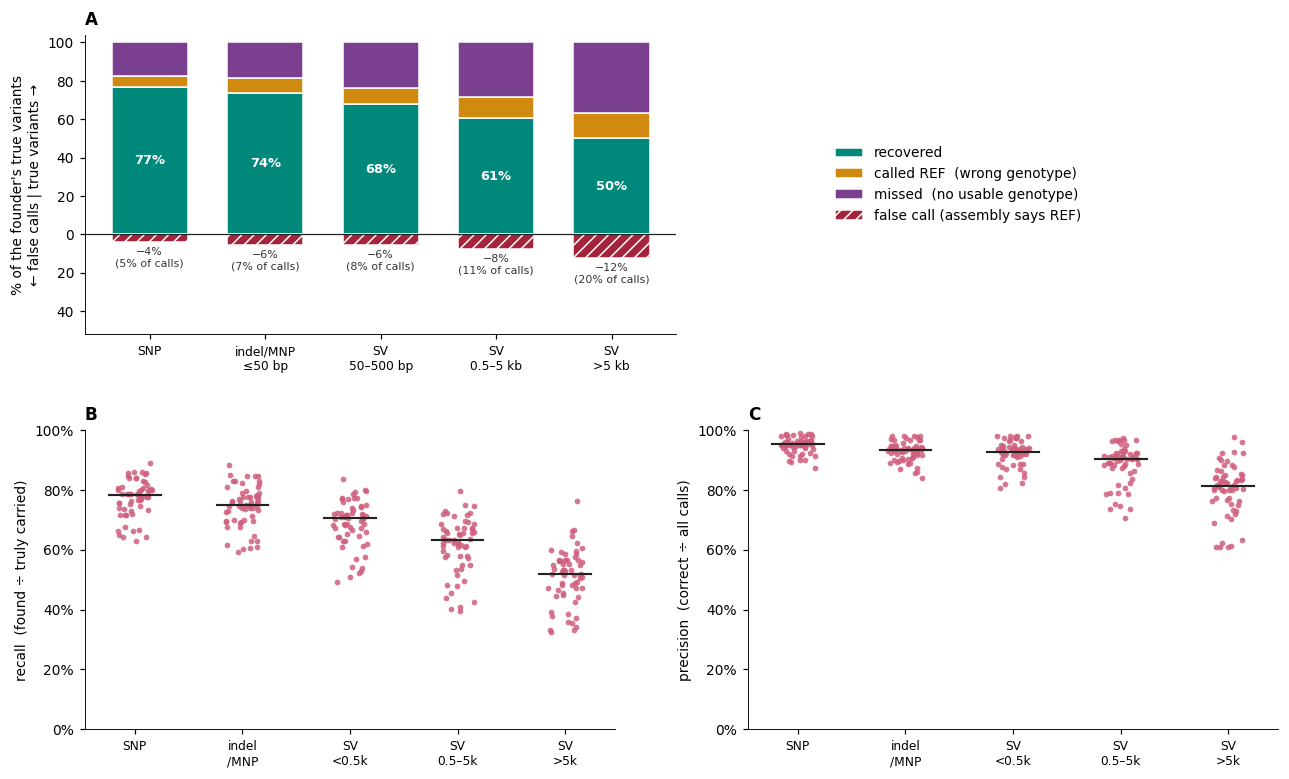

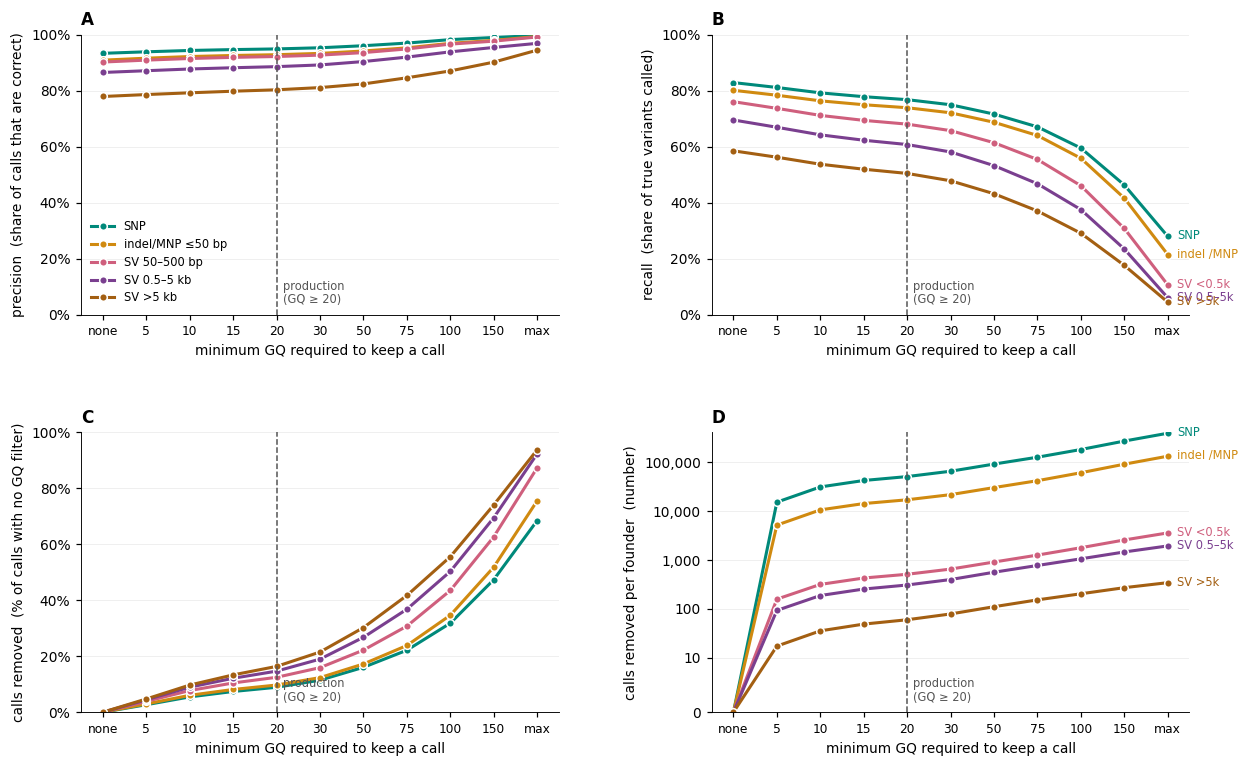

founder removed from the graph, production QC, no filter, pooled over 60 verified founders

                                                 SNP  indel/MNP ≤50 bp  SV 50–500 bp  SV 0.5–5 kb  SV >5 kb
recall                                         76.76             73.88         68.02        60.74     50.42
precision                                      94.88             92.82         92.17        88.55     80.28
nRD                                            11.51             15.12         17.33        23.71     33.37
% of PanGenie calls that are false              5.12              7.18          7.83        11.45     19.72
false calls per 100 true variants               4.14              5.71          5.78         7.85     12.38
% recovered                                    76.76             73.88         68.02        60.74     50.42
% called REF  (wrong genotype)                  5.85              7.44          8.48        11.02     12.87
% missed  (no usable genotype)              

In [8]:
def pooled(S, stage="prod"):
    g = S[S.stage == stage].groupby("size_class").sum(numeric_only=True).reindex(CLS)
    g["missed"] = g[MISSED].sum(axis=1)
    g["recall"] = g.recovered / g.truth_carriers
    g["precision"] = g.recovered / (g.recovered + g.fp)
    g["nRD"] = g.nonref_disc / g.nonref
    return g
def per_founder(S, stage="prod"):
    g = S[S.stage == stage].groupby(["ecotype", "size_class"]).sum(numeric_only=True)
    return pd.DataFrame(dict(recall=g.recovered / g.truth_carriers, nRD=g.nonref_disc / g.nonref,
                             precision=g.recovered / (g.recovered + g.fp))).reset_index()

G = pooled(S_lo)
fig = plt.figure(figsize=(14, 8.2))
outer = fig.add_gridspec(2, 1, hspace=0.32)
top = outer[0].subgridspec(1, 2, width_ratios=[1.3, 1], wspace=0.28)
bot = outer[1].subgridspec(1, 2, wspace=0.25)
# ax: 0 fates (A) · 1 recall (B) · 2 precision (C) · 3 legend slot for A
ax = [fig.add_subplot(top[0]), fig.add_subplot(bot[0]), fig.add_subplot(bot[1]), fig.add_subplot(top[1])]
ax[3].axis("off")
xx = np.arange(len(CLS)); bottom = np.zeros(len(CLS))
for f in FATE:
    v = 100 * G[f] / G.truth_carriers
    ax[0].bar(xx, v, 0.66, bottom=bottom, color=FATE[f], label=FATELAB[f],
              edgecolor="white", linewidth=1)
    bottom += v.values
fp = 100 * G.fp / G.truth_carriers                     # false calls, on the same scale
ax[0].bar(xx, -fp, 0.66, color=FALSE, hatch="///", edgecolor="white", linewidth=1,
          label="false call (assembly says REF)")
ax[0].axhline(0, color="#222", lw=0.8)
for i, (r, p, f_) in enumerate(zip(G.recall, G.precision, fp)):
    ax[0].annotate(f"{100*r:.0f}%", (i, 100*r/2), ha="center", va="center", color="white",
                   fontsize=8.5, fontweight="bold")
    ax[0].annotate(f"−{f_:.0f}%\n({100*(1-p):.0f}% of calls)", (i, -f_), xytext=(0, -3),
                   textcoords="offset points", ha="center", va="top", fontsize=7.2, color="#333")
ax[0].set_xticks(xx); ax[0].set_xticklabels([CLSLAB[c] for c in CLS], fontsize=8)
ax[0].set_ylim(-52, 104); ax[0].set_yticks(range(-40, 101, 20))
ax[0].set_yticklabels([f"{abs(v)}" for v in range(-40, 101, 20)])
ax[0].set_ylabel("% of the founder's true variants\n← false calls | true variants →")
h_, l_ = ax[0].get_legend_handles_labels()
ax[3].legend(h_, l_, frameon=False, fontsize=9, loc="center left")
panel(ax[0], "A", f"founder removed from the graph · production QC · {FLAB}")

A_lo = per_founder(S_lo)
rng_ = np.random.default_rng(0)
for k, metric, lab, letter in [(1, "recall", "recall  (found ÷ truly carried)", "B"),
                               (2, "precision", "precision  (correct ÷ all calls)", "C")]:
    a = ax[k]
    for i, c in enumerate(CLS):
        v = A_lo[A_lo.size_class == c][metric].values
        a.scatter(np.full(len(v), i) + rng_.uniform(-.16, .16, len(v)), v, s=14, color=GRP["trueloo"],
                  zorder=3, linewidths=0, alpha=0.85)
        a.plot([i - 0.24, i + 0.24], [np.median(v)] * 2, color="#222", lw=1.4, zorder=4)
    a.set_xticks(xx); a.set_xticklabels([CLSSHORT[c] for c in CLS], fontsize=8)
    a.yaxis.set_major_formatter(PercentFormatter(1.0)); a.set_ylabel(lab)
    panel(a, letter, f"each dot = one founder ({len(LOO)}) · line = median")
ax[1].set_ylim(0, 1); ax[2].set_ylim(0, 1)
# D: can a stricter GQ remove the false calls? (hom-alt calls surviving production QC)
FC = pd.concat([pd.read_csv(f, dtype={"size_class": str}).assign(ecotype=os.path.basename(f).split(".")[0])
                for f in glob.glob(f"{QC}/false_calls/*.csv.gz")], ignore_index=True)
FC = FC[FC.ecotype.isin(LOO) & (FC.baseline if FILTER == "baseline" else True)]
if MATCH == "events":                                   # SV calls as events (one row per called event)
    ev = EVRAW["trueloo"]; ev = ev[ev.called_any & ev.ecotype.isin(LOO) & (ev.baseline if FILTER == "baseline" else True)]
    FC = pd.concat([FC[~FC.size_class.str.startswith("sv")],
                    pd.DataFrame(dict(size_class=ev.size_class, truth=ev.truth.astype(int), gq=ev.gq_any, ecotype=ev.ecotype))],
                   ignore_index=True)
# full GQ curve: hom-alt calls at ANY GQ (GQ missing = fails every threshold but "none")
THR = [(None, "none"), (5, "5"), (10, "10"), (15, "15"), (20, "20"), (30, "30"), (50, "50"), (75, "75"),
       (100, "100"), (150, "150"), (10000, "max")]          # PanGenie GQ jumps from ~200 to its 10000 cap
CURVE = {"SNP": "#00897A", "small": "#D08A10", "sv_50_500": "#CF5F7D", "sv_500_5k": "#7A3F8F", "sv_5k": "#A35F12"}
plt.savefig(f"{PLOTS}/q1_recovery{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

# separate figure: what each GQ threshold buys (precision) and costs (recall)
rows = []
for c in CLS:
    x = FC[FC.size_class == c]; n_truth = G.loc[c, "truth_carriers"]
    for t, lab in THR:
        k = x if t is None else x[x.gq >= t]
        tp = (k.truth == 1).sum()
        rows.append(dict(size_class=c, gq=lab, recall=tp / n_truth, precision=tp / max(len(k), 1), calls=len(k)))
GQT = pd.DataFrame(rows)
n0 = GQT[GQT.gq == "none"].set_index("size_class").calls
GQT["lost_pct"] = 1 - GQT.calls / GQT.size_class.map(n0)                  # share of calls removed vs no GQ filter
GQT["lost_per_founder"] = (GQT.size_class.map(n0) - GQT.calls) / len(LOO)  # calls removed, per founder
xs = np.arange(len(THR)); i20 = [l for _, l in THR].index("20")
fig, ax2 = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw=dict(wspace=0.32, hspace=0.42))
ax2 = ax2.ravel()
for a, metric, lab in [(ax2[0], "precision", "precision  (share of calls that are correct)"),
                       (ax2[1], "recall", "recall  (share of true variants called)"),
                       (ax2[2], "lost_pct", "calls removed  (% of calls with no GQ filter)"),
                       (ax2[3], "lost_per_founder", "calls removed per founder  (number)")]:
    for c in CLS:
        v = GQT[GQT.size_class == c].set_index("gq").reindex([l for _, l in THR])[metric].values
        a.plot(xs, v, "-o", color=CURVE[c], lw=2, ms=5, mec="white", mew=1, label=CLSLAB[c].replace("\n", " "))
        if metric in ("recall", "lost_per_founder"):   # end labels only where the lines are apart
            a.annotate(CLSSHORT[c].replace("\n", " "), (xs[-1], v[-1]), xytext=(6, 0), textcoords="offset points",
                       va="center", fontsize=7.5, color=CURVE[c])
    a.axvline(i20, ls="--", lw=1, color="#555")
    a.annotate("production\n(GQ ≥ 20)", (i20, 0.04), xycoords=("data", "axes fraction"), xytext=(4, 0),
               textcoords="offset points", fontsize=7.5, color="#555")
    a.set_xticks(xs); a.set_xticklabels(["none"] + [l for _, l in THR[1:]], fontsize=8)
    a.set_xlabel("minimum GQ required to keep a call"); a.set_ylabel(lab)
    if metric == "lost_per_founder":
        a.set_yscale("symlog", linthresh=10); a.set_ylim(0, None)
        a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    else:
        a.set_ylim(0, 1); a.yaxis.set_major_formatter(PercentFormatter(1.0))
    a.grid(axis="y", color="#eee", lw=0.6); a.set_axisbelow(True)
panel(ax2[0], "A", "stricter →  fewer false calls"); panel(ax2[1], "B", "stricter →  more true variants lost")
panel(ax2[2], "C", "share of PanGenie calls the threshold removes")
panel(ax2[3], "D", f"same, as a number of calls per founder (mean over {len(LOO)})")
ax2[0].legend(frameon=False, fontsize=7.5, loc="lower left")
plt.savefig(f"{PLOTS}/q1_gq_threshold{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

T = (100 * G[["recall", "precision", "nRD"]]).round(2)
T["% of PanGenie calls that are false"] = (100 * (1 - G.precision)).round(2)
T["false calls per 100 true variants"] = (100 * G.fp / G.truth_carriers).round(2)
for f in list(FATE) + MISSED:
    T[f"% {FATELAB[f]}" if f not in MISSED else f"   of which: {FATELAB[f]}"] = (100 * G[f] / G.truth_carriers).round(2)
T["truth variants"] = G.truth_carriers.astype(int)
T.index = [CLSLAB[c].replace("\n", " ") for c in CLS]
print(f"founder removed from the graph, production QC, {FLAB}, pooled over {len(LOO)} verified founders\n")
print(T.T.to_string())
M = per_founder(S_lo).groupby("size_class")[["recall", "precision", "nRD"]].median()
print("\nmedian over founders, production QC (%)\n"); print((100 * M.reindex(CLS)).round(2).to_string())
print("\nGQ threshold sweep, founder removed (%): precision, then recall")
TD = GQT.assign(recall=lambda d: (100 * d.recall).round(1), precision=lambda d: (100 * d.precision).round(1))
for m in ("precision", "recall"):
    print(f"\n{m}"); print(TD.pivot(index="size_class", columns="gq", values=m).reindex(index=CLS, columns=[l for _, l in THR]).to_string())
print("\ncalls removed vs no GQ filter (%)")
print((100 * GQT.pivot(index="size_class", columns="gq", values="lost_pct")).round(1).reindex(index=CLS, columns=[l for _, l in THR]).to_string())
print(f"\ncalls removed vs no GQ filter, per founder (mean over {len(LOO)})")
print(GQT.pivot(index="size_class", columns="gq", values="lost_per_founder").round(0).astype(int)
      .reindex(index=CLS, columns=[l for _, l in THR]).to_string())
print("\ncalls kept with no GQ filter, per founder (mean):", (n0 / len(LOO)).round(0).astype(int).reindex(CLS).to_dict())
if MATCH == "exact":
    mech = FC[FC.truth == 0].groupby("size_class").bubble_nonref.mean().reindex(CLS)
    print("\nfalse calls in a bubble where the founder carries a different variant (substitution) (%)")
    print((100 * mech).round(1).to_string())
SS = pooled(S_lo_all[S_lo_all.ecotype.isin(SENS)])
print(f"\nsensitivity — verified + elevated ({S_lo_all[S_lo_all.ecotype.isin(SENS)].ecotype.nunique()} founders) "
      f"vs verified ({len(LOO)}), production QC (%)")
print(pd.concat({"verified": 100 * G[["recall", "precision"]], "verified+elevated": 100 * SS[["recall", "precision"]]},
                axis=1).round(2).to_string())
R = pooled(S_lo, "raw")
print("\nraw PanGenie output (no QC), founder removed: recall / nRD (%)"
      + (" — SNP/indel only; SV events are scored at production QC only" if MATCH == "events" else ""))
print((100 * R[["recall", "nRD"]]).round(2).T.dropna(axis=1).to_string())

### Where are the false SV calls — no filter

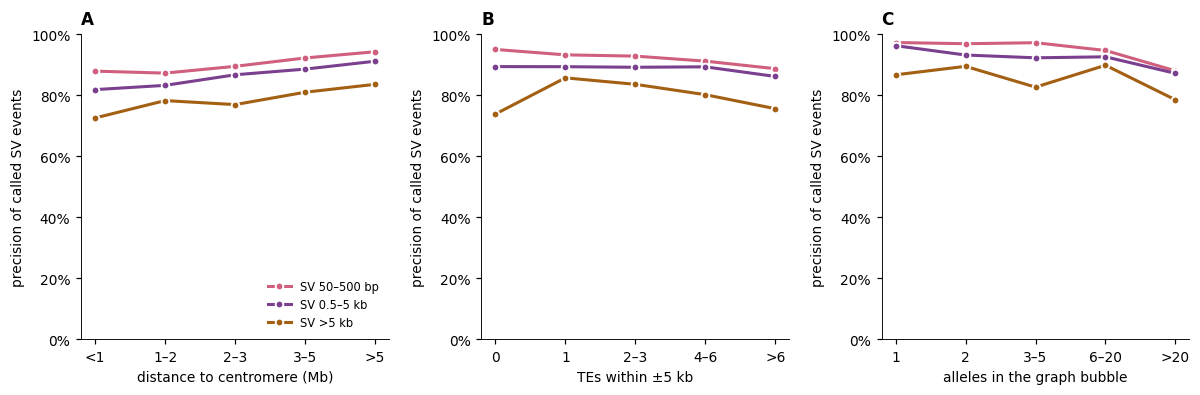

each mask: precision of the SV calls it keeps / % of TRUE SV calls it drops

size_class           sv_50_500  sv_500_5k  sv_5k  sv_50_500 lost  sv_500_5k lost  sv_5k lost
mask                                                                                        
none (production)         92.2       88.6   80.3             0.0             0.0         0.0
centromere ±1 Mb          92.4       88.9   80.7             4.8             4.1         5.0
centromere ±2 Mb          93.0       89.6   81.3            14.5            14.5        22.2
centromere ±3 Mb          93.7       90.3   82.6            27.2            30.0        39.1
>3 TEs within ±5 kb       93.7       89.3   82.6            41.3            52.9        50.3
>6 TEs within ±5 kb       93.0       89.3   81.7            17.8            23.1        22.1
bubble >5 alleles         97.2       93.5   86.0            73.8            90.9        93.1
bubble >20 alleles        95.9       92.9   88.4            44.9            75.0      

In [9]:
sys_path = __import__("sys").path
if QC not in sys_path: sys_path.insert(0, QC)
from precision_by_context import te_density, CEN
X = EVRAW["trueloo"]; X = X[X.called & X.ecotype.isin(LOO) & (X.baseline if FILTER == "baseline" else True)].reset_index(drop=True)
X["cen_mb"] = (X.pos - X.chrom.map(CEN)).abs() / 1e6
X["te"] = te_density(X)
SVC = ["sv_50_500", "sv_500_5k", "sv_5k"]
CTX = [("cen_mb", [0, 1, 2, 3, 5, 100], ["<1", "1–2", "2–3", "3–5", ">5"], "distance to centromere (Mb)"),
       ("te", [-1, 0, 1, 3, 6, 1000], ["0", "1", "2–3", "4–6", ">6"], "TEs within ±5 kb"),
       ("n_alleles", [0, 1, 2, 5, 20, 10000], ["1", "2", "3–5", "6–20", ">20"], "alleles in the graph bubble")]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(wspace=0.3))
for a, (col, bins, labs, xl) in zip(ax, CTX):
    b = pd.cut(X[col], bins, labels=labs)
    for c in SVC:
        g = X[X.size_class == c].groupby(b[X.size_class == c], observed=False).truth
        p, n = g.mean().reindex(labs), g.size().reindex(labs)
        a.plot(range(len(labs)), p.values, "-o", color=CURVE[c], lw=2, ms=5, mec="white", mew=1.2,
               label=CLSLAB[c].replace("\n", " "))
    a.set_xticks(range(len(labs))); a.set_xticklabels(labs); a.set_xlabel(xl)
    a.yaxis.set_major_formatter(PercentFormatter(1.0)); a.set_ylim(0, 1.0); a.set_ylabel("precision of called SV events")
for a, l in zip(ax, "ABC"):
    panel(a, l, "")
ax[0].legend(frameon=False, fontsize=7.5, loc="lower right")
plt.savefig(f"{PLOTS}/q1_precision_context{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

masks = {"none (production)": pd.Series(False, index=X.index), "centromere ±1 Mb": X.cen_mb < 1,
         "centromere ±2 Mb": X.cen_mb < 2, "centromere ±3 Mb": X.cen_mb < 3,
         ">3 TEs within ±5 kb": X.te > 3, ">6 TEs within ±5 kb": X.te > 6,
         "bubble >5 alleles": X.n_alleles > 5, "bubble >20 alleles": X.n_alleles > 20, "GQ < 100": X.gq < 100}
rows = []
for name, m in masks.items():
    for c in SVC:
        s_ = (X.size_class == c).values; keep, drop = s_ & ~m.values, s_ & m.values
        rows.append(dict(mask=name, size_class=c, precision=100 * X.truth[keep].mean(),
                         true_lost=100 * X.truth[drop].sum() / max(X.truth[s_].sum(), 1)))
MT = pd.DataFrame(rows)
print("each mask: precision of the SV calls it keeps / % of TRUE SV calls it drops\n")
print(MT.pivot(index="mask", columns="size_class", values="precision").reindex(index=list(masks), columns=SVC).round(1)
      .join(MT.pivot(index="mask", columns="size_class", values="true_lost").reindex(columns=SVC).round(1), rsuffix=" lost")
      .to_string())

### All founders against the GrENE-Net panel — no filter

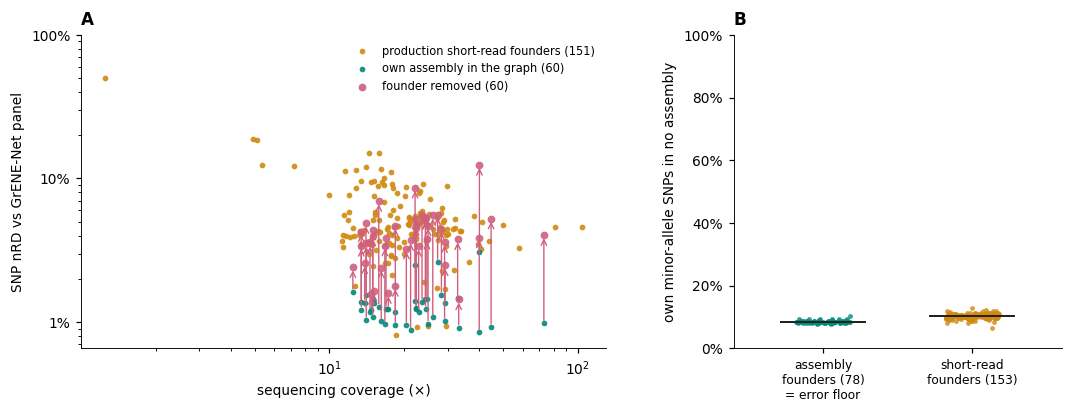

SNP nRD vs GrENE-Net, production QC — median (%) by group
group
own assembly in the graph (60)          1.31
founder removed (60)                    4.33
production short-read founders (151)    4.71

paired, same founders: own assembly in graph -> removed (%)
group  ingraph  trueloo
acc                    
10002     1.18     3.37
159       1.54     4.42
5784      2.61     5.61
5811      1.46     3.77
6150      0.91     1.44
6184      0.85     3.88
6244      0.87     3.71
6898      1.22     3.38
6911      3.06    12.42
6915      0.95     1.78
6929      1.23     1.59
6932      0.93     5.25
6938      1.44     3.80
6958      1.26     4.73
6963      1.37     2.56
6979      1.24     4.50
7000      1.03     3.53
7002      0.98     4.02
7003      1.01     2.40
7025      1.28     6.95
7063      2.51     8.61
7092      0.96     3.41
7143      1.01     3.60
7186      1.40     5.26
7217      1.24     3.86
7255      1.56     4.87
7288      0.98     4.70
7316      1.45     4.00
7323      1.24     5

In [10]:
GN = pd.read_csv(f"{QC}/grenenet_concordance_by_group.csv", dtype={"acc": str})
GN = GN[(GN.stage == "gq") & (GN["filter"] == FILTER)]
st = pd.read_csv(f"{P}/preprocess_qc/output/stage_aggregate.tsv", sep="\t", dtype={"ecotype": str})
cov = st.drop_duplicates("ecotype").set_index("ecotype").cov_est
GN["cov"] = GN.acc.map(cov)
GN.loc[GN.group == "loo", "group"] = "ingraph"; GN.loc[GN.group == "main", "group"] = "unseen"
GN = GN[~((GN.group == "ingraph") & GN.acc.isin(["5772", "9947"]))]
GN = GN[(GN.group == "unseen") | GN.acc.isin(VER)]          # assembly founders: verified only
GLAB = {"ingraph": f"own assembly in the graph ({(GN.group=='ingraph').sum()})",
        "trueloo": f"founder removed ({(GN.group=='trueloo').sum()})",
        "unseen": "production short-read founders (151)"}

O = pd.read_csv(f"{QC}/old_only_snps_per_founder.csv", dtype={"founder": str})
O["frac"] = O.n_old_only_not_in_graph / O.filter(like="n_").sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.3))
for g in ["unseen", "ingraph", "trueloo"]:
    d = GN[GN.group == g]
    ax[0].scatter(d["cov"], d.nRD, s=26 if g == "trueloo" else 14, color=GRP[g], linewidths=0,
                  alpha=0.9, label=GLAB[g], zorder=4 if g == "trueloo" else 3)
pair = GN[GN.group.isin(["ingraph", "trueloo"])].pivot(index="acc", columns="group", values="nRD").dropna()
for a, r in pair.iterrows():
    ax[0].annotate("", xy=(cov.get(a), r.trueloo), xytext=(cov.get(a), r.ingraph),
                   arrowprops=dict(arrowstyle="->", color="#CF5F7D", lw=0.9))
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_ylim(None, 1)   # log axis: up to 100%
ax[0].set_xlabel("sequencing coverage (×)"); ax[0].set_ylabel("SNP nRD vs GrENE-Net panel")
ax[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax[0].legend(frameon=False, fontsize=7.5, loc="upper right")
panel(ax[0], "A", f"each dot = one founder · production QC · {FLAB}")

rng = np.random.default_rng(0)
for i, s in enumerate(["cactus", "pangenie"]):
    v = O[O.source == s].frac.values
    ax[1].scatter(np.full(len(v), i) + rng.uniform(-.18, .18, len(v)), v, s=10, color=SRC[s],
                  linewidths=0, alpha=0.8)
    ax[1].plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color="#222", lw=1.3)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["assembly\nfounders (78)\n= error floor",
                                                 "short-read\nfounders (153)"], fontsize=8)
ax[1].yaxis.set_major_formatter(PercentFormatter(1.0)); ax[1].set_xlim(-0.6, 1.6); ax[1].set_ylim(0, 1)
ax[1].set_ylabel("own minor-allele SNPs in no assembly")
panel(ax[1], "B", "variation the graph never sees")
plt.savefig(f"{PLOTS}/q1_all_founders{SFX}.png", dpi=150, bbox_inches="tight"); plt.show()

print("SNP nRD vs GrENE-Net, production QC — median (%) by group")
print((100 * GN.groupby("group").nRD.median()).round(2).rename(GLAB).to_string())
if len(pair):
    print("\npaired, same founders: own assembly in graph -> removed (%)")
    print((100 * pair[["ingraph", "trueloo"]]).round(2).to_string())
print("\nshare of own minor-allele SNPs in no assembly (%)")
q = O.groupby("source").frac.describe()[["count", "25%", "50%", "75%"]]
q[["25%", "50%", "75%"]] *= 100
print(q.round(2).astype({"count": int}).to_string())

In [11]:
FILTER, SFX = "baseline", ""                    # back to the analysis filter for Q2
load_q1()

/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:65: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E["tp"] = E.truth & E.called; E["fpe"] = E.called & ~E.truth
/tmp/ipykernel_4089648/145538733.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

/tmp/ipykernel_4089648/145538733.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  E[f_] = E.fate == f_


## Q2 · The new panel against the old GrENE-Net phase-1 panel

Same 231 accessions, two panels: the **old** one is a short-read SNP call set
(Beagle-imputed, no missing genotypes); the **new** one is the production arch3 panel
(78 assembly + 153 PanGenie founders; SNPs, indels and SVs; production QC; segregating
records only). SNPs are matched on position and both alleles (`panel_vs_grenenet.py`).

- **A — content.** Which old SNPs the new panel has, and what it adds. Old SNPs missing from
  the new panel are split by where they sit in the graph: *outside any graph bubble* (all 135
  assemblies agree with the reference there), *inside a bubble* (often present in the new
  panel but written as part of a longer MNP/complex record rather than as this SNP), or *in
  the graph but not segregating* among the 231 in the new panel.
  Under the analysis filter, old SNPs present in the new panel but removed by the filter are
  their own category.
- **B — genotypes.** Per founder, nRD between the two panels at shared SNPs, and the share of
  those SNPs the new panel leaves missing.
- **C — allele frequencies.** Founder allele frequency (unweighted over the 231) per shared SNP.

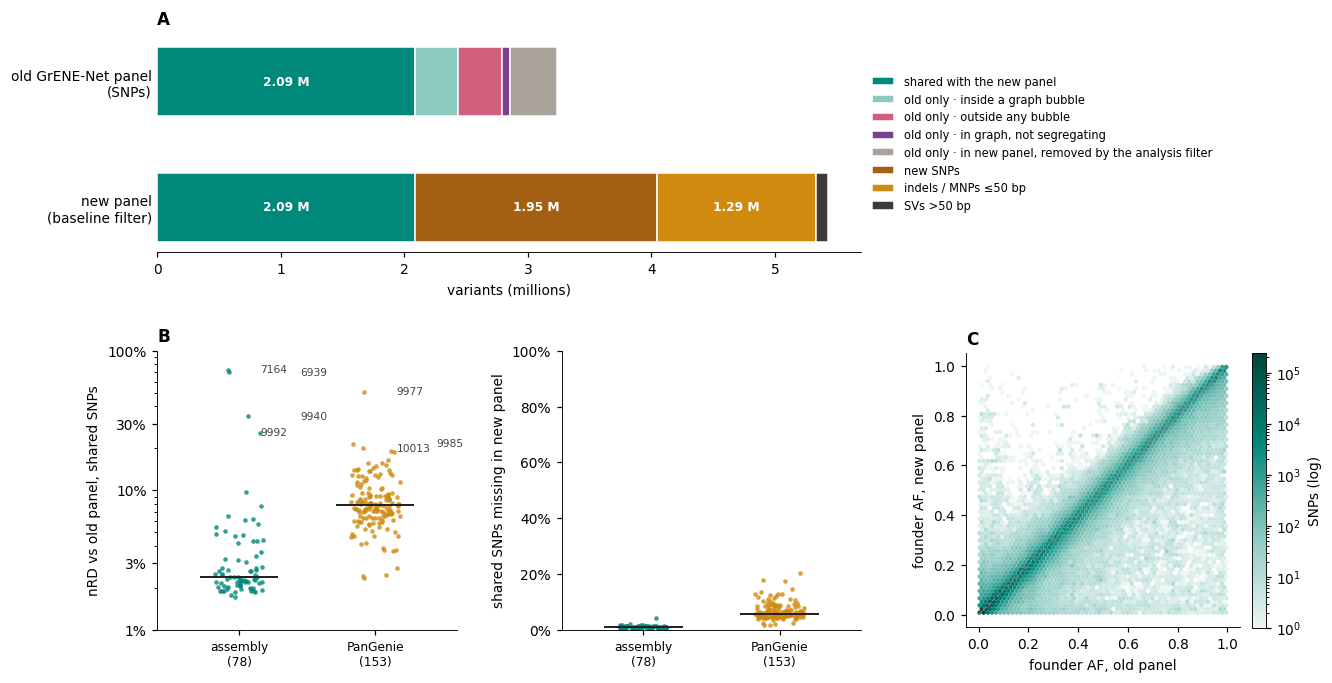

old SNPs 3,235,480: shared 2,089,663 (64.6%), old-only 1,145,817 [outside bubble 355,174, inside bubble 346,505, in graph not segregating 59,602, in new panel but removed by the filter 384,536]
new panel 5,426,896: SNPs 4,042,216 (new 1,952,553), indel/MNP 1,292,959, SV 91,721

per founder, shared SNPs (%) — median [IQR]
           nRD             missing_new            
          0.25  0.50  0.75        0.25  0.50  0.75
source                                            
cactus    2.09  2.39  3.55        0.77  0.98  1.23
pangenie  6.55  7.86  9.51        5.02  5.88  7.58

founder AF, 2,089,663 shared SNPs: r = 0.9876, mean |ΔAF| = 0.0119, |ΔAF| > 0.05: 3.83%, > 0.10: 1.29%


In [12]:
SITES = pd.read_csv(f"{QC}/panel_vs_grenenet_sites.csv"); SITES = SITES[SITES["filter"] == FILTER].sum(numeric_only=True)
OB = pd.read_csv(f"{QC}/old_only_snps_bubble.csv.gz")
nb = OB[OB["cat"] == "old_only_not_in_graph"].in_bubble.value_counts()   # not-in-graph SNPs: same under any filter
CC = pd.read_csv(f"{QC}/panel_class_counts.csv"); CC = CC[CC["filter"] == FILTER].groupby("size_class").n.sum()
F = pd.read_csv(f"{QC}/panel_vs_grenenet_founders.csv", dtype={"founder": str}); F = F[F["filter"] == FILTER]
AF = dict(np.load(f"{QC}/panel_vs_grenenet_af.npz"))
if FILTER == "baseline":
    AF = {k: v[AF["baseline"]] for k, v in AF.items()}

fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.3], hspace=0.4, wspace=0.35)
a = fig.add_subplot(gs[0, :2])
old_parts = [("shared with the new panel", SITES.shared, "#00897A"),
             ("old only · inside a graph bubble", nb.get(True, 0), "#8CC9C0"),
             ("old only · outside any bubble", nb.get(False, 0), "#CF5F7D"),
             ("old only · in graph, not segregating", SITES.old_only_in_graph, "#7A3F8F"),
             ("old only · in new panel, removed by the analysis filter", SITES.old_only_filtered_out, "#A8A29A")]
new_parts = [("shared with the new panel", SITES.shared, "#00897A"),
             ("new SNPs", SITES.new_only, "#A35F12"),
             ("indels / MNPs ≤50 bp", CC["small"], "#D08A10"),
             ("SVs >50 bp", CC[["sv_50_500", "sv_500_5k", "sv_5k"]].sum(), "#3F3A36")]
for y, parts in [(1, old_parts), (0, new_parts)]:
    left = 0
    for lab, n, col in parts:
        a.barh(y, n / 1e6, 0.55, left=left, color=col, edgecolor="white", linewidth=1,
               label=lab if not (y == 0 and lab.startswith("shared")) else None)
        if n / 1e6 > 0.6:
            a.annotate(f"{n/1e6:.2f} M", (left + n / 2e6, y), ha="center", va="center",
                       color="white", fontsize=8, fontweight="bold")
        left += n / 1e6
a.set_yticks([1, 0]); a.set_yticklabels(["old GrENE-Net panel\n(SNPs)", "new panel\n(baseline filter)"])
a.set_xlabel("variants (millions)"); a.spines["left"].set_visible(False); a.tick_params(axis="y", length=0)
a.legend(frameon=False, fontsize=7.5, ncol=1, loc="center left", bbox_to_anchor=(1.0, 0.5))
panel(a, "A", "content", y=1.04)

b = fig.add_subplot(gs[1, 0]); b2 = fig.add_subplot(gs[1, 1]); c = fig.add_subplot(gs[1, 2])
rng = np.random.default_rng(1)
for axx, metric, lab in [(b, "nRD", "nRD vs old panel, shared SNPs"),
                         (b2, "missing_new", "shared SNPs missing in new panel")]:
    for i, s in enumerate(["cactus", "pangenie"]):
        v = F[F.source == s][metric].values
        axx.scatter(np.full(len(v), i) + rng.uniform(-.18, .18, len(v)), v, s=9, color=SRC[s],
                    linewidths=0, alpha=0.8)
        axx.plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color="#222", lw=1.3)
    axx.set_xticks([0, 1]); axx.set_xticklabels(["assembly\n(78)", "PanGenie\n(153)"], fontsize=8)
    axx.set_xlim(-0.6, 1.6); axx.yaxis.set_major_formatter(PercentFormatter(1.0)); axx.set_ylabel(lab)
    if metric == "missing_new":
        axx.set_ylim(0, 1)
b.set_yscale("log"); b.set_yticks([0.01, 0.03, 0.1, 0.3, 1]); b.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
for k, (_, r) in enumerate(F[F.nRD > 0.2].sort_values("nRD").iterrows()):   # stagger close pairs
    b.annotate(r.founder, ({"cactus": 0, "pangenie": 1}[r.source], r.nRD), xytext=(14 + 26 * (k % 2), 0),
               textcoords="offset points", fontsize=7, color="#444", va="center")
panel(b, "B", "each dot = one founder"); panel(b2, "", "")
ok = np.isfinite(AF["af_old"]) & np.isfinite(AF["af_new"])
hb = c.hexbin(AF["af_old"][ok], AF["af_new"][ok], gridsize=60, bins="log", cmap=TEAL_SEQ, mincnt=1,
              linewidths=0)
c.plot([0, 1], [0, 1], ls="--", lw=0.8, color="#888")
c.set_xlabel("founder AF, old panel"); c.set_ylabel("founder AF, new panel"); c.set_aspect("equal")
fig.colorbar(hb, ax=c, fraction=0.046, pad=0.04, label="SNPs (log)")
panel(c, "C", "shared SNPs")
plt.savefig(f"{PLOTS}/q2_panel_vs_grenenet.png", dpi=150, bbox_inches="tight"); plt.show()

d = np.abs(AF["af_old"][ok] - AF["af_new"][ok])
print(f"old SNPs {SITES.old_snps:,.0f}: shared {SITES.shared:,.0f} ({100*SITES.shared/SITES.old_snps:.1f}%), "
      f"old-only {SITES.old_only:,.0f} [outside bubble {nb.get(False,0):,}, inside bubble {nb.get(True,0):,}, "
      f"in graph not segregating {SITES.old_only_in_graph:,.0f}, in new panel but removed by the filter {SITES.old_only_filtered_out:,.0f}]")
print(f"new panel {CC.sum():,}: SNPs {CC['SNP']:,} (new {SITES.new_only:,.0f}), indel/MNP {CC['small']:,}, "
      f"SV {CC[['sv_50_500','sv_500_5k','sv_5k']].sum():,}")
print("\nper founder, shared SNPs (%) — median [IQR]")
q = F.groupby("source")[["nRD", "missing_new"]].quantile([.25, .5, .75]).unstack()
print((100 * q).round(2).to_string())
print(f"\nfounder AF, {ok.sum():,} shared SNPs: r = {np.corrcoef(AF['af_old'][ok], AF['af_new'][ok])[0,1]:.4f}, "
      f"mean |ΔAF| = {d.mean():.4f}, |ΔAF| > 0.05: {100*(d>0.05).mean():.2f}%, > 0.10: {100*(d>0.10).mean():.2f}%")

### Allele frequencies at a stricter call rate

The same founder allele-frequency comparison as panel C, side by side for the baseline filter
(call rate ≥ 50%) and the stricter call rate ≥ 90% some analyses use (both with ≥ 2 carriers),
on one colour scale. Call rate is the share of the 231 founders the new panel genotypes at
that SNP.

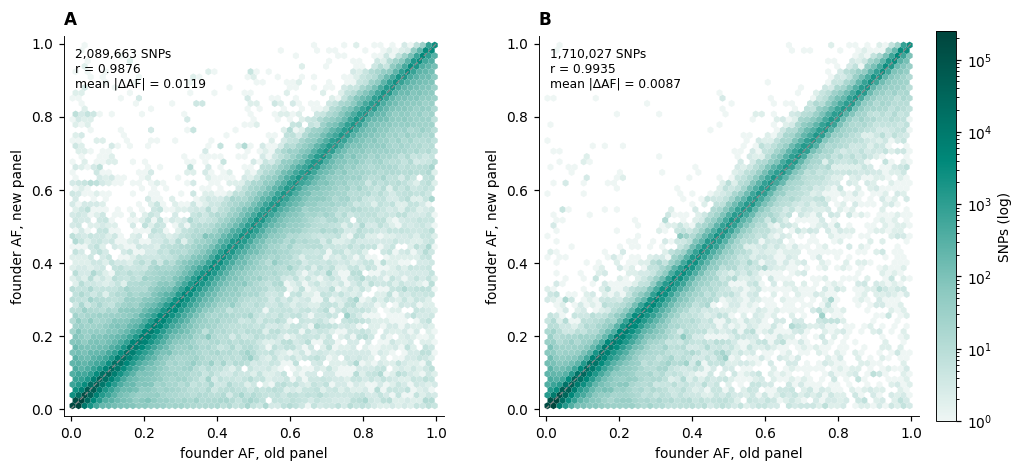

call rate ≥ 50%  (baseline)   2,089,663 SNPs  r = 0.9876  mean |ΔAF| = 0.0119  |ΔAF| > 0.05: 3.83%  > 0.10: 1.29%
call rate ≥ 90%               1,710,027 SNPs  r = 0.9935  mean |ΔAF| = 0.0087  |ΔAF| > 0.05: 1.84%  > 0.10: 0.54%


In [13]:
AF0 = dict(np.load(f"{QC}/panel_vs_grenenet_af.npz"))
ok0 = np.isfinite(AF0["af_old"]) & np.isfinite(AF0["af_new"]) & AF0["baseline"]
cr = AF0["called_new"] / N_F
SETS = [("call rate ≥ 50%  (baseline)", ok0), ("call rate ≥ 90%", ok0 & (cr >= 0.9))]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6), gridspec_kw=dict(wspace=0.25))
vmax = None
for a, (lab, m) in zip(ax, SETS):
    hb = a.hexbin(AF0["af_old"][m], AF0["af_new"][m], gridsize=60, bins="log", cmap=TEAL_SEQ, mincnt=1,
                  linewidths=0, vmin=1, vmax=vmax)
    vmax = vmax or hb.get_array().max()
    a.plot([0, 1], [0, 1], ls="--", lw=0.8, color="#888")
    a.set_xlim(-0.02, 1.02); a.set_ylim(-0.02, 1.02); a.set_aspect("equal")
    a.set_xlabel("founder AF, old panel"); a.set_ylabel("founder AF, new panel")
    dd = np.abs(AF0["af_old"][m] - AF0["af_new"][m])
    a.annotate(f"{m.sum():,} SNPs\nr = {np.corrcoef(AF0['af_old'][m], AF0['af_new'][m])[0, 1]:.4f}\n"
               f"mean |ΔAF| = {dd.mean():.4f}", (0.03, 0.97), xycoords="axes fraction", va="top", fontsize=8)
panel(ax[0], "A", SETS[0][0]); panel(ax[1], "B", SETS[1][0])
fig.colorbar(hb, ax=ax, fraction=0.025, pad=0.02, label="SNPs (log)")
plt.savefig(f"{PLOTS}/q2_af_callrate.png", dpi=150, bbox_inches="tight"); plt.show()
for lab, m in SETS:
    dd = np.abs(AF0["af_old"][m] - AF0["af_new"][m])
    print(f"{lab:28s} {m.sum():>10,} SNPs  r = {np.corrcoef(AF0['af_old'][m], AF0['af_new'][m])[0,1]:.4f}  "
          f"mean |ΔAF| = {dd.mean():.4f}  |ΔAF| > 0.05: {100*(dd>0.05).mean():.2f}%  > 0.10: {100*(dd>0.10).mean():.2f}%")

**Reading it.** _(filled in once the numbers are reviewed)_